# Assignment 10

### <span style="color:chocolate"> Submission requirements </span>

Your work will not be graded if your notebook doesn't include output. In other words, <span style="color:red"> make sure to rerun your notebook before submitting to Gradescope </span> (Note: if you are using Google Colab: go to Edit > Notebook Settings  and uncheck Omit code cell output when saving this notebook, otherwise the output is not printed).

Additional points may be deducted if these requirements are not met:
    
* Comment your code;
* Each graph should have a title, labels for each axis, and (if needed) a legend. Each graph should be understandable on its own;
* Try and minimize the use of the global namespace (meaning, keep things inside functions).

---

#### ``Objectives``
1. Implement a CNN to detect diabetic retinopathy (DR) from retina images taken using fundus photography under a variety of imaging conditions.
2. Improve generalization performance and reduce overfitting using **image transformation** and **data augmentation** techniques.

#### ``Motivation``

Diabetic retinopathy (DR) is an eye condition that  affects blood vessels in the retina. It can cause vision loss and blindness in people who have diabetes. Screening for DR allows earlier and more effective treatment options for millions of people.

#### ``Data``

In this assignment you will use a small dataset of retina images (`Download` links: [images](https://drive.google.com/drive/folders/1sdfUC64Un1iwuiHEehcbijxB54OhU_nd?usp=sharing) and [labels](https://drive.google.com/drive/folders/1MOlSJBZg7L1HtG5vHPt77ighRvQaGfDg?usp=sharing)). You will **build** and **train** a **CNN model** to predict whether or not to refer a patient for DR treatment using binarized severity of DR in patients: no referral if {No DR, mild} and referral if {moderate, severe, and proliferate DR}.


<u>Note</u>: the original dataset is hosted by Kaggle [[Source]](https://www.kaggle.com/c/aptos2019-blindness-detection/).

Import the necessary libraries and make sure to replace IMAGE_PATH and LABEL_PATH with the path to the directories where you saved the data.

---
### Step 1: Import libraries

In [1]:
# standard
import pandas as pd
import numpy as np
import random
import os

# tf and keras
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img
from keras import models
from keras import layers

# sklearn
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# plots
import seaborn as sns
import matplotlib.pyplot as plt

random.seed(2)
%matplotlib inline

IMAGE_PATH = '/Users/i/Downloads/CNN_images/'
LABEL_PATH = '/Users/i/Downloads/CNN_labels/'

At this point, you may ask yourself what the best model that fits this data is. First, you will want to read through the data description in Kaggle (see the link to the original dataset above). Understanding what you are working with challenges you to write preprocessing code that uncovers your data's most helpful information.

---
#### <span style="color:chocolate"> Exercise 1 (10 points) </span>

Read the data description from Kaggle and list (a) the source of images and (b) the labeling procedure.

*Written answer*:

The APTOS 2019 Blindness Detection competition describes its data as retinal fundus photographs collected in India under varied imaging conditions and with different cameras. Clinicians graded each image for diabetic retinopathy severity on a five-level scale: 0 (No DR), 1 (mild), 2 (moderate), 3 (severe), and 4 (proliferative DR). For this assignment, grades 0–1 are grouped as no refer and grades 2–4 as refer.


---
### Step 2: Data ingestion

Let's load the 2D images and their corresponding labels.

``labels``

In [2]:
labels = pd.read_csv(
    LABEL_PATH + 'labels.csv'
)

print('Shape of labels:', labels.shape)
print('Unique diagnosis codes:', np.sort(labels.diagnosis.unique()))
labels.head()

Shape of labels: (200, 2)
Unique diagnosis codes: [0 1 2 3 4]


,id_code,diagnosis
0,000c1434d8d7,2
1,0024cdab0c1e,1
2,0083ee8054ee,4
3,00a8624548a9,2
4,00b74780d31d,2


There are 200 training images corrresponding to 5 different diabetic retinopathy (DR) diagnosis codes: 

* No DR (0)
* mild (1)
* moderate (2)
* severe (3)
* proliferate DR (4)


``images``

In [3]:
images = []

for idx, img in enumerate(os.listdir(IMAGE_PATH)):
    img = load_img(
    IMAGE_PATH + img)
    images.append(img)

---
### Step 3: Exploratory Data Analysis (EDA)

#### <span style="color:chocolate"> Exercise 2 (10 points) </span>

Plot a histogram for the five classes of DR. Are the classes balanced?


Note: It's acceptable to plot the distribution of classes before splitting your data into training, validation, and test sets. Doing so does not compromise the "blindness" of the test data. Why?

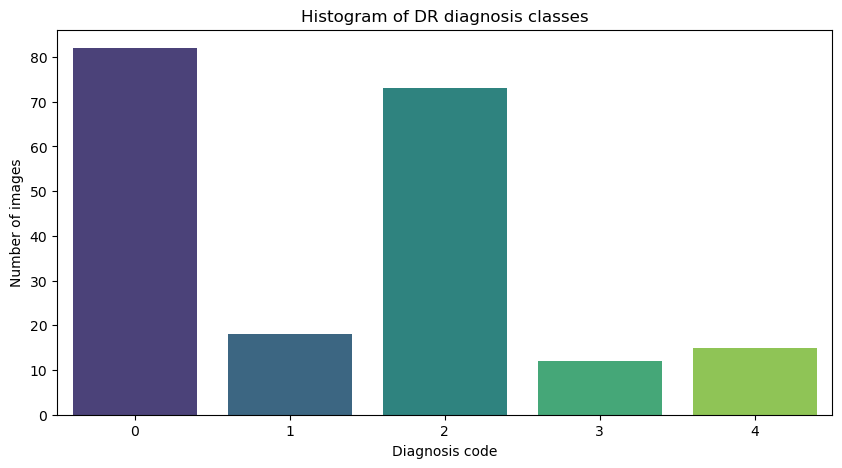

Class counts by diagnosis code:
diagnosis
0    82
1    18
2    73
3    12
4    15
Name: count, dtype: int64


In [4]:
diagnosis_counts = labels['diagnosis'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=diagnosis_counts.index.astype(str),
    y=diagnosis_counts.values,
    hue=diagnosis_counts.index.astype(str),
    palette='viridis',
    legend=False
)
plt.title('Histogram of DR diagnosis classes')
plt.xlabel('Diagnosis code')
plt.ylabel('Number of images')
plt.xticks(rotation=0)
plt.show()

print('Class counts by diagnosis code:')
print(diagnosis_counts)


Comment on class balance:

The 200 labels are imbalanced across the five diagnosis grades: 82 grade 0, 18 grade 1, 73 grade 2, 12 grade 3, and 15 grade 4. After binarizing the labels, the full dataset is evenly split between 100 no-refer cases (grades 0–1) and 100 refer cases (grades 2–4). Plotting these label counts is descriptive only; it does not train a model or use test-image features or predictions, so it does not reveal test performance.


#### <span style="color:chocolate"> Exercise 3 (10 points) </span>

Print 8 images from the data. What can you say about the size, focus/orientation of these images?

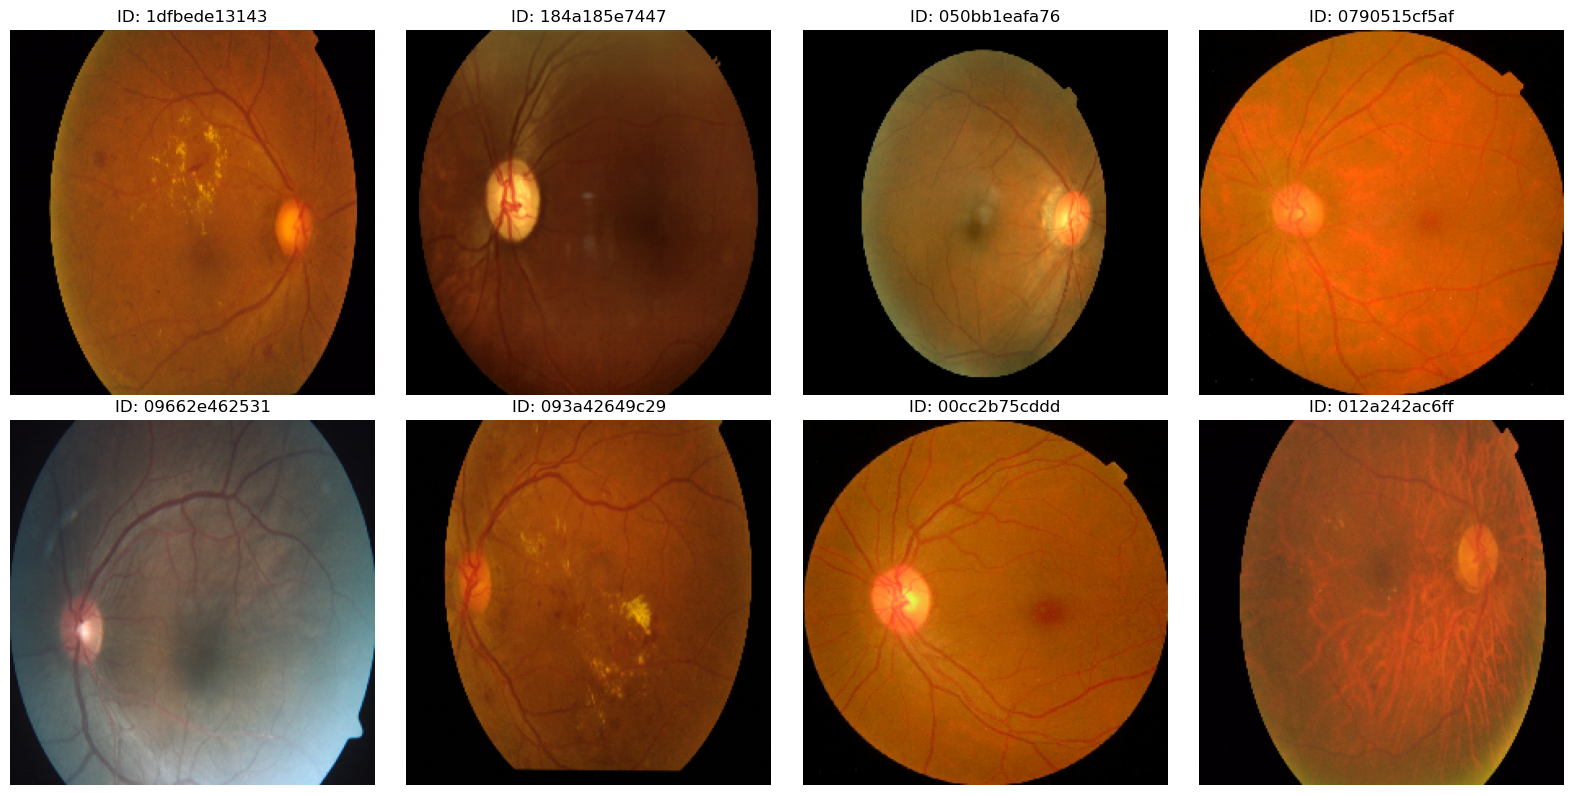

In [5]:
sample_ids = labels.sample(n=8, random_state=1234).id_code.tolist()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for ax, img_id in zip(axes, sample_ids):
    candidate_paths = [
        os.path.join(IMAGE_PATH, f'{img_id}.png'),
        os.path.join(IMAGE_PATH, f'{img_id}.jpeg'),
        os.path.join(IMAGE_PATH, f'{img_id}.jpg')
    ]
    img_path = next((p for p in candidate_paths if os.path.exists(p)), None)
    if img_path is None:
        continue
    img = load_img(img_path, target_size=(224, 224))
    ax.imshow(img)
    ax.set_title(f'ID: {img_id}')
    ax.axis('off')

plt.tight_layout()
plt.show()


Comment on the size, focus/orientation of the 8 images:

The eight displayed images range from 819 x 614 to 4288 x 2848 pixels, with one square image at 1050 x 1050. They show circular retinal fields with black borders. Brightness, color, sharpness, and framing vary, and the optic disc appears on different sides. The notebook resizes images to 224 x 224 x 3 before training.


---
### Step 4: Data preprocessing

First, we will correct for class imbalance. Note that imbalanced data is common in healthcare, and it happens because some diseases are rare. The presence of imbalanced data hampers the detection of rare events as most classification methods implicitly assume a similar occurrence of classes and are designed to maximize the overall classification accuracy.

We will correct for class imbalance in two ways:

  * First, we will binarize the DR diagnosis as follows:
     - 'no refer' are {No DR, mild}
     - 'refer' are {Moderate, Severe, Proliferate}


  * Second, we'll only take 80 random samples from the 'no refer' class and 80 from the 'refer' class.

It is a crude method to deal with imbalanced data, but it will be good enough for this homework. 

In [6]:
np.random.seed(1234)

no_refer = labels[labels.diagnosis.isin((0,1))]
refer = labels[labels.diagnosis.isin((2,3,4))]

# randomly draw 80 images from each classes
temp_no_refer = list(np.random.choice(
    no_refer.id_code,
    size=80,
    replace=False
))

temp_refer = list(np.random.choice(
    refer.id_code,
    size=80,
    replace=False
))

Next, we will use the ``preprocess_data_part1()`` function defined below to generate lists of images and labels (images_mini and y_mini) based on the values in the temp_no_refer and temp_refer lists. Note that the size of the image is set to (224, 224).

In [7]:
def preprocess_data_part1(IMAGE_PATH, LABEL_PATH, temp_no_refer, temp_refer):
    """ Generate lists of images and labelsbased on temp_no_refer and temp_refer lists
    
    Params:
    -------
    IMAGE_PATH (str): path to directory with images.
    LABEL_PATH (str): path to directory with labels.
    temp_no_refer (str): list of labels for the no refer category
    temp_refer (str): list of labels for the refer category
    
    Returns:
    --------
    images_mini  (np.ndarray): Images of shape (N, 224, 224, 3)
    y_mini (np.ndarray): Labels of shape (N,)    
    """
    y_mini = []
    images_mini = []

    # create lists of images and labels `images_mini` and `y_mini` 
    # based on temp_no_refer and temp_refer selections
    for idx, img in enumerate(os.listdir(IMAGE_PATH)):
        # read labels
        if img.split('.')[0] in temp_no_refer:
                y_mini.append(0)
        elif img.split('.')[0] in temp_refer:
                y_mini.append(1)
        else:
            continue

        
        # read image
        img = load_img(
            IMAGE_PATH + img,
            target_size=(224, 224)
        )
        
        # transform image to array
        img = img_to_array(img)

        # append to images
        images_mini.append(img)

    # stack images and trasnform to array
    images_mini = np.stack(images_mini)
    y_mini = np.array(y_mini).flatten() 
    
    return images_mini, y_mini

In [8]:
# generate images and labels based on preprocess_data_part1() function
images_mini, y_mini = preprocess_data_part1(
    IMAGE_PATH, LABEL_PATH, temp_no_refer, temp_refer
)

print(f"images_mini shape {images_mini.shape}")
print(f"y_mini shape {y_mini.shape}")

images_mini shape (160, 224, 224, 3)
y_mini shape (160,)


#### <span style="color:chocolate"> Exercise 4 (20 points) </span>

Create train, validation, and test data. Implement the `preprocess_data_part2()` function according to the following guidelines:

1. shuffle images and labels before splitting the data

2. use a (0.6,0.2,0.2)train/validation/test set split

3. perform image transformation and augmentation, as follows:
    * Applied on training set only:
         - create additional copies (augmentations) of the training images by flipping left right each image (Hint: use the method available in the tf.image module).
         - concatenate the augmented images to the original training images. Note that the train set should be double in size after data augmentation, i.e., 192 images and labels.
    * Applied on training, validation, and test sets:
        - rescale images by dividing each pixel by 255.0

Reason for doing image augmentation: The quantity and diversity of data gathered significantly impact the results of a CNN model. One can use augmentations to artificially inflate the training dataset by warping the original data so that their label does not change. These augmentations can significantly improve learning results without collecting new data.

In [9]:
def preprocess_data_part2(images, labels, splits):
    """Shuffle, split, augment the training set, and normalize all images."""
    tf.random.set_seed(1234)
    np.random.seed(1234)

    # Shuffle images and labels together before creating the requested splits.
    indices = np.random.permutation(len(images))
    images = np.asarray(images)[indices]
    labels = np.asarray(labels)[indices]

    n_total = len(images)
    n_train = int(splits[0] * n_total)
    n_val = int(splits[1] * n_total)
    X_train, y_train = images[:n_train], labels[:n_train]
    X_val, y_val = images[n_train:n_train + n_val], labels[n_train:n_train + n_val]
    X_test, y_test = images[n_train + n_val:], labels[n_train + n_val:]

    # Add one left-right flipped copy of every training image.
    X_train_augm = tf.image.flip_left_right(tf.convert_to_tensor(X_train))
    X_train = tf.concat([X_train, X_train_augm], axis=0).numpy()
    y_train = np.concatenate([y_train, y_train], axis=0)

    # Shuffle the expanded training set without separating images from labels.
    shuffle = tf.random.shuffle(tf.range(tf.shape(X_train)[0], dtype=tf.int32))
    X_train = tf.gather(X_train, shuffle).numpy()
    y_train = tf.gather(y_train, shuffle).numpy()

    # Scale pixels in all three splits to [0, 1].
    X_train = X_train.astype(np.float32) / 255.0
    X_val = X_val.astype(np.float32) / 255.0
    X_test = X_test.astype(np.float32) / 255.0

    return X_train, y_train, X_val, y_val, X_test, y_test


In [10]:
# define splits
split = (0.6, 0.2, 0.2)

X_train, y_train, X_val, y_val, X_test, y_test = preprocess_data_part2(
    images_mini,
    y_mini,
    split
)

print(f"X_train shape {X_train.shape}")
print(f"y_train shape {y_train.shape}")
print(f"X_val shape {X_val.shape}")
print(f"y_val shape {y_val.shape}")
print(f"X_test shape {X_test.shape}")
print(f"y_test shape {y_test.shape}")

X_train shape (192, 224, 224, 3)
y_train shape (192,)
X_val shape (32, 224, 224, 3)
y_val shape (32,)
X_test shape (32, 224, 224, 3)
y_test shape (32,)


---
### Step 5: Modeling

#### <span style="color:chocolate"> Exercise 5 (20 points) </span>

The objective is to build and train a CNN model to refer patients to doctors based on the severity of DR seen in these images. You are interested in exploring binary classification of 'no refer' and 'refer'.

Implement a CNN classifier according to the following guidelines (let's call this *model_tf*):

1. Implement this model using the TF Keras API.
1. The model receives input images of size 224 x 224 x 3 (that is, the images have three color channels)
2. The input data goes through one convolutional layer that has the following specifications:
    - filters = 12
    - kernel_size = (4 x 4)
    - strides = (1, 1)
    - padding = 'same'
    - data_format = 'channels_last'
    - name = 'conv_1'
    - activation = 'relu'
3. The convolutional layer is followed by a max-pooling layer with pool_size = (2,2). Note: this will reduce the size of the feature maps.
4. The max-pooling layer is followed by a dropout layer with rate = 0.3.
5. The dropout layer is followed by a flattening layer.
6. The last layer of the model is the classification head.
7. Build and compile the model using the Adam optimizer and learning_rate = 0.1. Print summary of the model.
8. Train the model on (X_train, y_train) data for 20 epochs. Add early stopping (Hint: pass the early_stopping implementation below to the fit() method as "callbacks=[early_stopping]").
9. How many parameters does the model have?
10. Generate a plot (for the training and validation data) with the loss values on the y-axis and the epoch number on the x-axis for visualization. Make sure to include axes name and title. Hint: check what the tf.keras.Model.fit() method returns.
11. Evaluate the accuracy of the model on (X_train, y_train) and (X_val, y_val) data. Comment on model performance on training vs. validation datasets. 

In [11]:
# define an instance of the early_stopping class
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    verbose=1,
    patience=5,
    mode='max',
    restore_best_weights=True
)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_1 (Conv2D)                 │ (None, 224, 224, 12)   │           588 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 12)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 12)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 150528)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │       150,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 151,117 (590.30 KB)

 Trainable params: 151,117 (590.30 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20


... (45 outputs left out)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 122ms/step - accuracy: 0.5078 - loss: 0.6958

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step - accuracy: 0.5312 - loss: 0.6917 - val_accuracy: 0.3438 - val_loss: 0.7266


Epoch 6: early stopping


Restoring model weights from the end of the best epoch: 1.


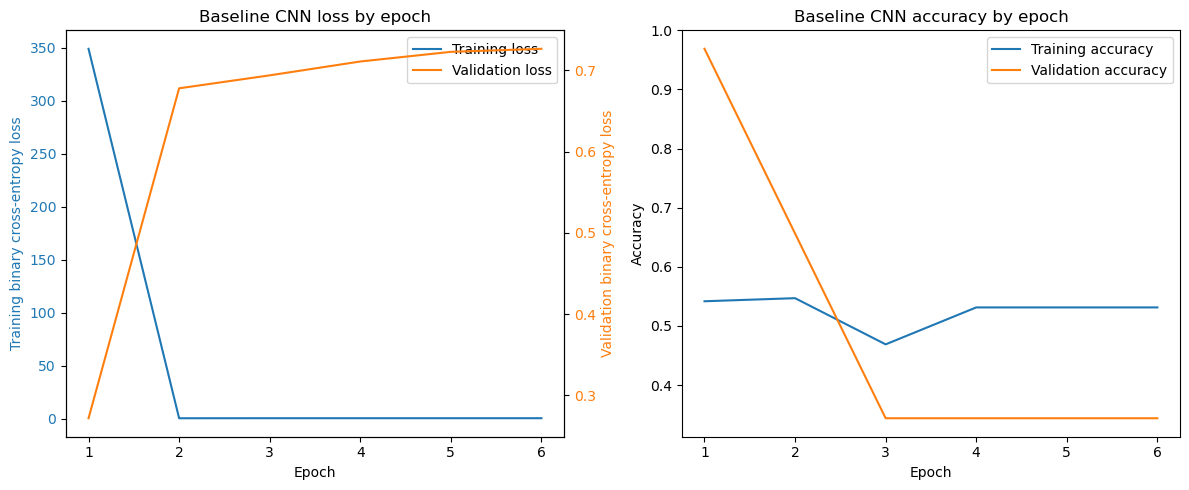

Baseline loss by epoch (training, validation):
    loss  val_loss
349.2205    0.2719
  0.6530    0.6780
  0.6942    0.6940
  0.6909    0.7110
  0.6907    0.7229
  0.6917    0.7266


Baseline parameter count: 151117
Training accuracy: 0.8177
Validation accuracy: 0.9688


In [12]:
tf.random.set_seed(1234)
np.random.seed(1234)

# Define the CNN architecture specified in the assignment.
model_tf = tf.keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(
        filters=12, kernel_size=(4, 4), strides=(1, 1), padding="same",
        data_format="channels_last", activation="relu", name="conv_1"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(1, activation="sigmoid")
])

model_tf.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.1),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy"]
)
model_tf.summary()

history = model_tf.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=20, batch_size=32, callbacks=[early_stopping], verbose=1
)

# Plot loss on separate y-axes so the large training-loss spike does not hide validation loss.
history_df = pd.DataFrame(history.history)
fig, (loss_ax, accuracy_ax) = plt.subplots(1, 2, figsize=(12, 5))
epochs = history_df.index + 1
train_line, = loss_ax.plot(epochs, history_df["loss"], color="tab:blue", label="Training loss")
loss_ax.set_title("Baseline CNN loss by epoch")
loss_ax.set_xlabel("Epoch")
loss_ax.set_ylabel("Training binary cross-entropy loss", color="tab:blue")
loss_ax.tick_params(axis="y", labelcolor="tab:blue")
validation_ax = loss_ax.twinx()
validation_line, = validation_ax.plot(epochs, history_df["val_loss"], color="tab:orange", label="Validation loss")
validation_ax.set_ylabel("Validation binary cross-entropy loss", color="tab:orange")
validation_ax.tick_params(axis="y", labelcolor="tab:orange")
loss_ax.legend([train_line, validation_line], [train_line.get_label(), validation_line.get_label()], loc="best")

accuracy_ax.plot(epochs, history_df["accuracy"], label="Training accuracy")
accuracy_ax.plot(epochs, history_df["val_accuracy"], label="Validation accuracy")
accuracy_ax.set_title("Baseline CNN accuracy by epoch")
accuracy_ax.set_xlabel("Epoch")
accuracy_ax.set_ylabel("Accuracy")
accuracy_ax.legend()
fig.tight_layout()
plt.show()

print("Baseline loss by epoch (training, validation):")
print(history_df[["loss", "val_loss"]].round(4).to_string(index=False))

train_acc = model_tf.evaluate(X_train, y_train, verbose=0)[1]
val_acc = model_tf.evaluate(X_val, y_val, verbose=0)[1]
print(f"Baseline parameter count: {model_tf.count_params()}")
print(f"Training accuracy: {train_acc:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")


How many parameters does *model_tf* have?

The baseline model has 151,117 parameters.


Comment on *model_tf* accuracy on training vs. validation data:

The baseline model reached 81.77% accuracy on the augmented training set and 96.88% on the validation set. Validation accuracy is higher in this run, so there is no observed training-greater-than-validation pattern here. Since the validation set contains only 32 images, its accuracy is a noisy estimate and should not be treated as proof of strong generalization.


#### <span style="color:chocolate"> Exercise 6 (20 points) </span>

1. Fine-tune the number of hidden layers and the hyperparameters of *model_tf* to determine the setup that yields the most optimal generalization performance. Feel free to explore various model configurations/hyperparameter values.

2. How many parameters does your fine-tuned model have?

3. Evaluate the accuracy of the fine-tuned model on (X_train, y_train) and (X_val, y_val) data. Comment on model performance on training vs. validation datasets.  Is there an improvement compared to the non-fine-tuned version of the model (Exercise 5)?

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,697 (100.38 KB)

 Trainable params: 25,697 (100.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40


... (445 outputs left out)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step - accuracy: 0.8588 - loss: 0.3489

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step - accuracy: 0.8698 - loss: 0.3469 - val_accuracy: 0.9688 - val_loss: 0.3037


Epoch 32: early stopping


Restoring model weights from the end of the best epoch: 26.


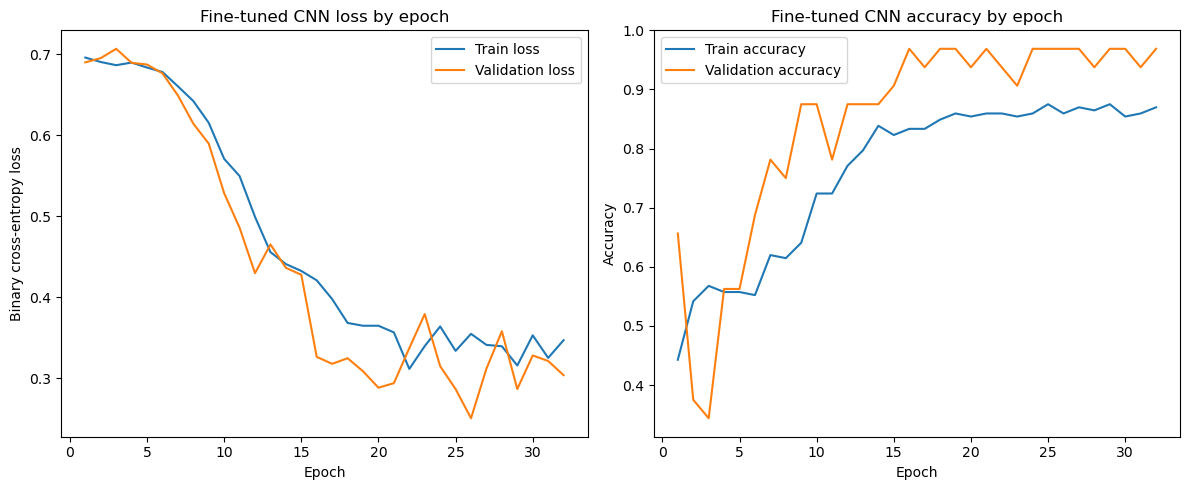

Fine-tuned model parameter count: 25697
Training accuracy (fine-tuned): 0.8906
Validation accuracy (fine-tuned): 0.9688


In [13]:
tf.random.set_seed(1234)
np.random.seed(1234)

# Use a compact deeper CNN with global average pooling to limit parameters.
model_ft = tf.keras.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.35),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(1, activation="sigmoid")
])

model_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.BinaryCrossentropy(),
    metrics=["accuracy"]
)
model_ft.summary()

history_ft = model_ft.fit(
    X_train, y_train, validation_data=(X_val, y_val),
    epochs=40, batch_size=16,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, mode="min", restore_best_weights=True, verbose=1
    )],
    verbose=1
)

history_ft_df = pd.DataFrame(history_ft.history)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history_ft_df.index + 1, history_ft_df["loss"], label="Train loss")
plt.plot(history_ft_df.index + 1, history_ft_df["val_loss"], label="Validation loss")
plt.title("Fine-tuned CNN loss by epoch")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_ft_df.index + 1, history_ft_df["accuracy"], label="Train accuracy")
plt.plot(history_ft_df.index + 1, history_ft_df["val_accuracy"], label="Validation accuracy")
plt.title("Fine-tuned CNN accuracy by epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

ft_train_acc = model_ft.evaluate(X_train, y_train, verbose=0)[1]
ft_val_acc = model_ft.evaluate(X_val, y_val, verbose=0)[1]
print(f"Fine-tuned model parameter count: {model_ft.count_params()}")
print(f"Training accuracy (fine-tuned): {ft_train_acc:.4f}")
print(f"Validation accuracy (fine-tuned): {ft_val_acc:.4f}")


How many parameters does your fine-tuned model have?

The fine-tuned model has 25,697 parameters.


Comment on accuracy of the fine-tuned model on training vs. validation performance. Is there an improvement over the non-fine-tuned version?

The fine-tuned model reached 89.06% accuracy on the augmented training set and 96.88% on validation. Validation accuracy matches the baseline rather than improving, while training accuracy is higher. The fine-tuned model has fewer parameters (25,697 versus 151,117) because global average pooling avoids the baseline model’s large flattened feature vector. On these results, the tuning did not improve validation accuracy; the test-set result is considered separately in Exercise 7.


---
### Step 6: Evaluation

#### <span style="color:chocolate"> Exercise 7 (10 points) </span>

You will now use the test data to evaluate the performance (accuracy) of your fine-tuned model on unseen data. Does your model generalize well?

Test accuracy: 0.7500
Test loss: 0.4697


Confusion matrix (rows: true, columns: predicted; no refer, refer):
[[10  8]
 [ 0 14]]


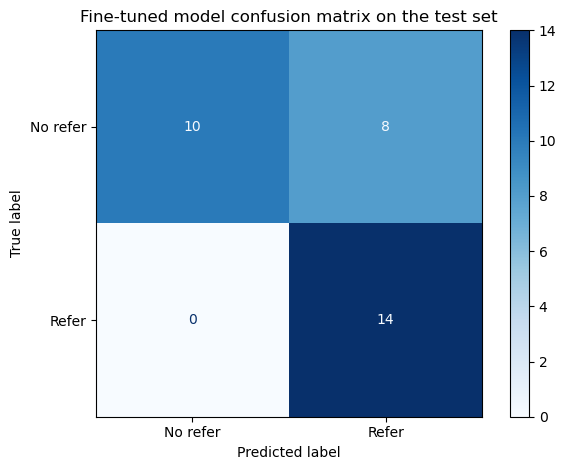

In [14]:
test_loss, test_acc = model_ft.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

y_pred = (model_ft.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)
cm = confusion_matrix(y_test.astype(int), y_pred)
print("Confusion matrix (rows: true, columns: predicted; no refer, refer):")
print(cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No refer", "Refer"])
disp.plot(cmap="Blues")
plt.title("Fine-tuned model confusion matrix on the test set")
plt.tight_layout()
plt.show()


Does your model generalize well?

The fine-tuned model achieved 75.00% accuracy (24 of 32 images) on the held-out test set, compared with 96.88% on validation. The test confusion matrix, with rows and columns ordered as no refer then refer, was [[10, 8], [0, 14]]. Thus, it correctly identified all 14 referred cases in this test sample, but incorrectly marked 8 of 18 no-refer cases as refer. Given the lower test score and the small test set, I would describe the evidence for generalization as limited rather than strong.
